In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler

In [3]:
X, y = make_moons(
    n_samples=300,
    noise=0.08,
    random_state=42
)

print("Dataset created successfully")
print(X[:5])

Dataset created successfully
[[ 0.65880058 -0.35596254]
 [ 1.98630199 -0.13348998]
 [-0.11162344  0.4550811 ]
 [ 0.90500816  0.26679823]
 [ 1.18161893 -0.49496507]]


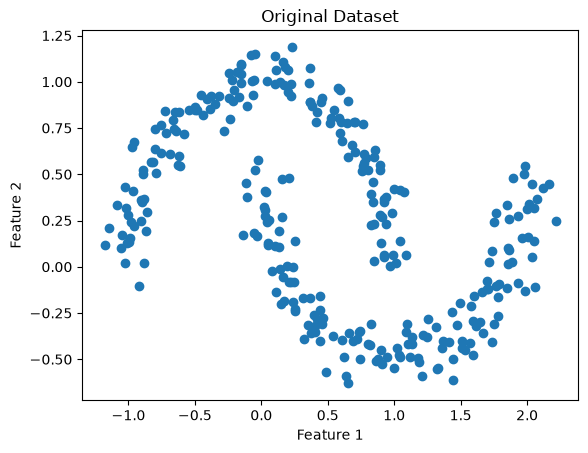

In [4]:
plt.scatter(X[:, 0], X[:, 1])

plt.title("Original Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.show()

In [5]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Data scaled successfully")

Data scaled successfully


In [6]:
dbscan = DBSCAN(
    eps=0.3,
    min_samples=5
)

dbscan.fit(X_scaled)

print("DBSCAN clustering completed")

DBSCAN clustering completed


In [7]:
labels = dbscan.labels_

print("Cluster Labels:")
print(labels)

Cluster Labels:
[0 0 0 1 0 0 0 1 1 0 0 1 0 1 0 0 0 0 1 0 1 1 0 0 1 1 0 0 0 0 1 0 1 1 0 1 1
 1 1 1 1 1 0 1 1 1 0 0 1 0 0 1 0 1 0 0 1 1 0 1 0 1 1 0 0 1 1 0 1 0 1 1 0 0
 1 0 1 1 1 0 0 0 1 1 1 1 1 1 1 1 0 1 1 0 1 1 0 1 0 1 0 1 1 0 0 0 1 1 0 1 1
 0 1 0 0 1 1 0 0 0 1 0 0 0 1 0 1 1 0 0 1 1 0 1 0 0 0 0 0 1 1 1 0 1 0 0 1 1
 1 1 0 1 0 0 0 0 0 1 0 1 0 0 1 1 1 1 0 0 0 1 1 0 0 1 1 0 1 1 0 1 0 1 0 0 1
 0 0 0 1 1 1 0 0 0 0 1 0 0 1 0 1 1 1 0 0 0 0 1 1 1 1 0 1 1 0 1 1 0 0 1 1 0
 0 0 1 0 1 1 0 0 1 0 0 0 0 1 1 1 0 0 0 0 0 1 0 1 0 0 0 1 1 1 1 1 1 1 1 1 0
 1 1 1 0 1 1 0 0 1 0 0 1 1 0 0 0 0 0 1 1 0 0 1 0 0 0 0 1 1 0 1 1 0 1 0 1 0
 1 1 0 1]


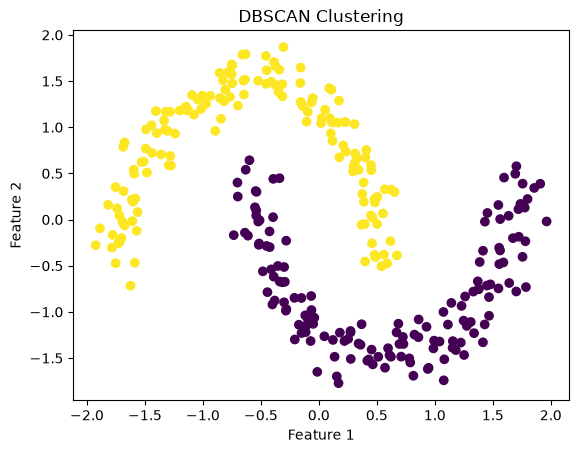

In [8]:
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels,
    cmap='viridis'
)

plt.title("DBSCAN Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.show()

In [9]:
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

n_noise = list(labels).count(-1)

print("Number of Clusters:", n_clusters)

print("Number of Noise Points:", n_noise)

Number of Clusters: 2
Number of Noise Points: 0


In [10]:
unique, counts = np.unique(labels, return_counts=True)

for cluster, count in zip(unique, counts):
    print("Cluster", cluster, ":", count, "points")

Cluster 0 : 150 points
Cluster 1 : 150 points
